# 05 · Conformal validity: comparing methods

**Goal:** Compare four approaches on the validity question (FPR on ID data at level α):
1. **naive TOOD** (batch-level, transductive): fails under contamination.
2. **ref_aphd one-sided**: valid but sensitive to signal direction.
3. **ref_aphd two-sided**: valid regardless of direction, but loses power.
4. **ensemble (Fisher)**: combines ref_aphd + iforest + msp with Fisher's method.

We measure FPR on clean ID rows at contamination levels π ∈ {0, 0.1, 0.3, 0.5} for two OOD scenarios.
The target is α = 0.05. Each method is run over 10 seeds (the full protocol).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from conformal_trees.conformal import (
    conformal_pvalues,
    empirical_fpr,
    fisher_combined_pvalue,
    two_sided_pvalues,
)
from conformal_trees.data import build_covariate_shifts, load_dataset, make_splits, mix_batch
from conformal_trees.models import GBDTClassifier, TreeEmbedder
from conformal_trees.signals import IsolationForestScore, msp_score, reference_score, tood_batch_score
from conformal_trees.utils import load_config, set_global_seed

pd.set_option("display.max_columns", 50)
cfg = load_config("base.yaml", "models.yaml", "ood_scenarios.yaml")
ALPHA = cfg["conformal"]["alpha"]
SEEDS = cfg["project"]["seeds"]
set_global_seed(SEEDS[0])

ds = load_dataset("adult")

## Full protocol: 10 seeds × 2 scenarios × 4 contamination levels × 4 methods

In [2]:
records = []
for seed in SEEDS:
    sp = make_splits(ds.X, ds.y, cfg["splits"], seed=seed)
    e = TreeEmbedder.from_config(cfg["embedder"], ds.numeric, ds.categorical, seed=seed).fit(sp.train.X, sp.train.y)
    gbdt = GBDTClassifier.from_config(cfg["gbdt"], seed=seed).fit(sp.train.X, sp.train.y)
    ifor = IsolationForestScore(ds.numeric, ds.categorical, seed=seed).fit(sp.train.X)

    scen = {s.name: s for s in build_covariate_shifts(cfg, sp.train.X, ds.numeric)}
    e_cal, e_ref = e.transform(sp.calib.X), e.transform(sp.calib_fit.X)
    e_test = e.transform(sp.test.X)

    # Calibration scores for each signal
    cal_ref = reference_score(e_cal, e_ref)
    cal_ifor = ifor.score(sp.calib.X)
    cal_msp = msp_score(gbdt.predict_proba(sp.calib.X)[:, 1])
    cal_batch = tood_batch_score(e_cal)

    for scen_name in ("mean_shift@1", "gaussian_noise@2"):
        X_ood = scen[scen_name].apply(sp.test.X, seed=seed)
        for pi in (0.0, 0.1, 0.3, 0.5):
            batch_X, is_ood = mix_batch(sp.test.X, X_ood, pi, seed=seed)
            batch_emb = e.transform(batch_X)

            # Test scores (only on ID rows)
            test_ref = reference_score(batch_emb[~is_ood], e_ref)
            test_ifor = ifor.score(batch_X.iloc[np.where(~is_ood)[0]])
            test_msp = msp_score(gbdt.predict_proba(batch_X.iloc[np.where(~is_ood)[0]])[:, 1])
            test_batch = tood_batch_score(batch_emb)[~is_ood]

            # Method 1: naive TOOD (batch-level)
            p_tood = conformal_pvalues(cal_batch, test_batch)
            records.append({"seed": seed, "scenario": scen_name, "pi": pi, "method": "naive TOOD",
                            "fpr": empirical_fpr(p_tood, ALPHA)})

            # Method 2: ref_aphd one-sided
            p_ref = conformal_pvalues(cal_ref, test_ref)
            records.append({"seed": seed, "scenario": scen_name, "pi": pi, "method": "ref_aphd (1-sided)",
                            "fpr": empirical_fpr(p_ref, ALPHA)})

            # Method 3: ref_aphd two-sided
            p_ref_2s = two_sided_pvalues(cal_ref, test_ref)
            records.append({"seed": seed, "scenario": scen_name, "pi": pi, "method": "ref_aphd (2-sided)",
                            "fpr": empirical_fpr(p_ref_2s, ALPHA)})

            # Method 4: ensemble (Fisher on ref_aphd + iforest + msp, all one-sided)
            p_ensemble = fisher_combined_pvalue(np.column_stack([
                conformal_pvalues(cal_ref, test_ref),
                conformal_pvalues(cal_ifor, test_ifor),
                conformal_pvalues(cal_msp, test_msp),
            ]))
            records.append({"seed": seed, "scenario": scen_name, "pi": pi, "method": "ensemble (Fisher)",
                            "fpr": empirical_fpr(p_ensemble, ALPHA)})

validity = pd.DataFrame(records)
validity.head()

d:\Development\projects for master\Paper researcher\Conformalized Tree-Based Gradient Ensembles for Out-of-Distribution Detection and Recourse\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Development\projects for master\Paper researcher\Conformalized Tree-Based Gradient Ensembles for Out-of-Distribution Detection and Recourse\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\Development\projects for master\Paper researcher\Conformalized Tree-Based Gradient Ensembles for Out-of-Distribution Detection and Recourse\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprec

,seed,scenario,pi,method,fpr
0,0,mean_shift@1,0.0,naive TOOD,0.033883
1,0,mean_shift@1,0.0,ref_aphd (1-sided),0.049647
2,0,mean_shift@1,0.0,ref_aphd (2-sided),0.045143
3,0,mean_shift@1,0.0,ensemble (Fisher),0.060088
4,0,mean_shift@1,0.1,naive TOOD,0.025136


In [3]:
summary = validity.groupby(["scenario", "pi", "method"])["fpr"].agg(["mean", "std"]).reset_index()
print(f"Target α = {ALPHA}\n")
display(summary.pivot_table(index=["scenario", "method"], columns="pi", values=["mean", "std"]).round(4))

Target α = 0.05



mean                             std  \
pi                                      0.0     0.1     0.3     0.5     0.0   
scenario         method                                                       
gaussian_noise@2 ensemble (Fisher)   0.0609  0.0608  0.0608  0.0617  0.0030   
                 naive TOOD          0.0477  0.0461  0.0429  0.0399  0.0074   
                 ref_aphd (1-sided)  0.0470  0.0469  0.0473  0.0472  0.0031   
                 ref_aphd (2-sided)  0.0481  0.0477  0.0477  0.0486  0.0029   
mean_shift@1     ensemble (Fisher)   0.0609  0.0608  0.0608  0.0617  0.0030   
                 naive TOOD          0.0477  0.0374  0.0121  0.0015  0.0074   
                 ref_aphd (1-sided)  0.0470  0.0469  0.0473  0.0472  0.0031   
                 ref_aphd (2-sided)  0.0481  0.0477  0.0477  0.0486  0.0029   

                                                             
pi                                      0.1     0.3     0.5  
scenario         method                                      
gaussian_noise@2 ensemble (Fisher)   0.0032  0.0031  0.0044  
                 naive TOOD          0.0073  0.0077  0.0079  
                 ref_aphd (1-sided)  0.0030  0.0041  0.0041  
                 ref_aphd (2-sided)  0.0026  0.0043  0.0040  
mean_shift@1     ensemble (Fisher)   0.0032  0.0031  0.0044  
                 naive TOOD          0.0071  0.0088  0.0046  
                 ref_aphd (1-sided)  0.0030  0.0041  0.0041  
                 ref_aphd (2-sided)  0.0026  0.0043  0.0040

## Visualization: FPR vs contamination π

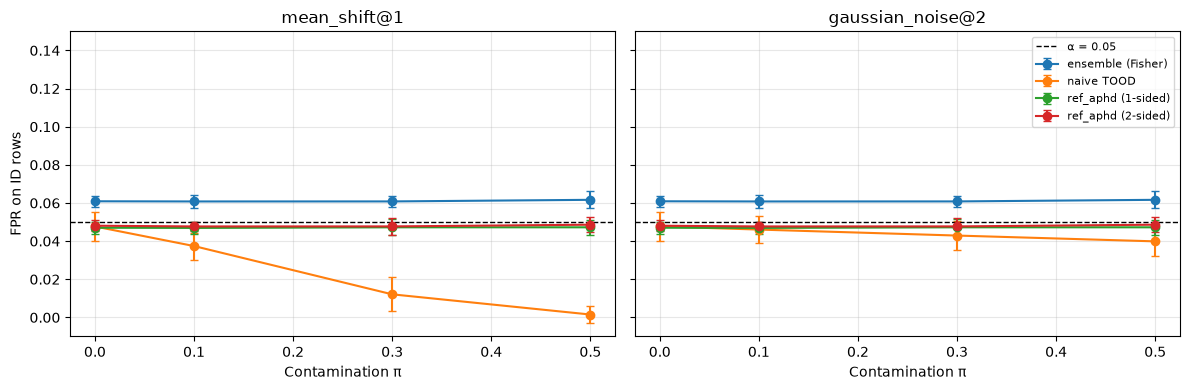

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, scen in zip(axes, ("mean_shift@1", "gaussian_noise@2")):
    sub = summary[summary["scenario"] == scen]
    for method, g in sub.groupby("method"):
        ax.errorbar(g["pi"], g["mean"], yerr=g["std"], marker="o", label=method, capsize=3)
    ax.axhline(ALPHA, color="k", ls="--", lw=1, label=f"α = {ALPHA}")
    ax.set_xlabel("Contamination π")
    ax.set_title(scen)
    ax.set_ylim(-0.01, 0.15)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("FPR on ID rows")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Key observations to carry into `docs/decisions.md`
- Does **naive TOOD** stay ≤ α at π=0, and does it exceed α at π > 0?
- Is **ref_aphd one-sided** stable across both scenarios, or does it fail on gaussian_noise (due to signal inversion)?
- Does **ref_aphd two-sided** stay valid everywhere (FPR ≤ α regardless of π or scenario)?
- Is **ensemble** the most stable: valid everywhere and tighter than two-sided?
- At high π, which methods collapse (FPR → 0, rejecting everything) and which stay controlled?